# EDA логов LogHub для детекции аномалий в распределённых облачных системах

Разведочный анализ четырёх датасетов из коллекции [LogHub](https://github.com/logpai/loghub): **BGL**, **Windows**, **HealthApp**, **Apache**.

Цель — изучить структуру строк, категориальные распределения, шаблоны событий и временную динамику логов, чтобы обосновать выбор признаков и подхода для последующей модели детекции аномалий.

## Данные

Все данные загружаются из [LogHub](https://github.com/logpai/loghub) (Zenodo, запись 3227177) через функцию `load_loghub` из модуля `util.loghub`. При первом запуске функция скачивает архивы и распаковывает их в `data/raw/`, при повторных — использует кэш.

| Датасет | Домен | Строк | Метки аномалий |
|---|---|---|---|
| BGL | суперкомпьютер BlueGene/L | 4 747 963 | есть (первое поле строки) |
| Windows | системные события Windows CBS | 114 608 388 | нет |
| HealthApp | логи Android-приложения | 253 395 | нет |
| Apache | веб-сервер Apache (error log) | 56 481 | нет |

Windows занимает ~26 ГБ в распакованном виде, поэтому для него берётся случайная выборка 1 000 000 строк методом reservoir sampling — равномерно по всему файлу (см. `load_windows`).

Лицензия: датасеты доступны для научной работы при ссылке на репозиторий LogHub и цитировании статьи [Loghub: A Large Collection of System Log Datasets for AI-driven Log Analytics](https://arxiv.org/abs/2008.06448).

## Настройка и воспроизводимость

Фиксируем генератор случайных чисел, подключаем модуль `util` и настраиваем отображение. Ноутбук рассчитан на выполнение от начала до конца из корня проекта.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline


def find_project_root() -> Path:
    start = Path.cwd().resolve()
    for parent in (start, *start.parents):
        if (parent / "util" / "loghub.py").exists():
            return parent
    return start


PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT))

from util.loghub import load_loghub, extract_templates, DATASETS

SEED = 42
WINDOWS_SAMPLE_SIZE = 1_000_000

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
pd.set_option("display.max_rows", 30)

In [2]:
def value_counts_df(series, top=10):
    counts = series.value_counts(dropna=False)
    return pd.DataFrame({"count": counts, "percent": (counts / counts.sum() * 100).round(2)}).head(top)


def template_table(df, top=20):
    templates = extract_templates(df["message"])
    counts = templates.value_counts()
    table = counts.head(top).rename_axis("template").reset_index(name="count")
    table["percent"] = (table["count"] / len(df) * 100).round(2)
    return table, counts


def plot_events_per_interval(df, rule, title, anomaly_col=None, ylabel="событий"):
    series = df.set_index("timestamp").resample(rule).size()
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.plot(series.index, series.values, lw=0.7, color="#1f77b4", label="все события")
    if anomaly_col is not None:
        anomalies = df[df[anomaly_col]].set_index("timestamp").resample(rule).size()
        ax.plot(anomalies.index, anomalies.values, lw=0.9, color="#d62728", label="аномалии")
        ax.legend()
    ax.set_title(title)
    ax.set_xlabel("время")
    ax.set_ylabel(ylabel)
    plt.tight_layout()
    plt.show()

In [3]:
datasets = {
    "BGL": load_loghub("BGL"),
    "Windows": load_loghub("Windows", windows_sample_size=WINDOWS_SAMPLE_SIZE, seed=SEED),
    "HealthApp": load_loghub("HealthApp"),
    "Apache": load_loghub("Apache"),
}

BGL: пропущено строк с неполной структурой: 34470


Windows: случайная выборка 1000000 строк из 114608388


Windows: пропущено строк, не соответствующих формату: 1632


In [4]:
overview_rows = []
for name, df in datasets.items():
    span = df["timestamp"].max() - df["timestamp"].min()
    overview_rows.append(
        {
            "датасет": name,
            "домен": DATASETS[name]["description"],
            "записей": len(df),
            "охват, дней": round(span.total_seconds() / 86400, 1),
            "колонок": df.shape[1],
            "есть метки аномалий": "is_anomaly" in df.columns,
        }
    )
pd.DataFrame(overview_rows).set_index("датасет")

,домен,записей,"охват, дней",колонок,есть метки аномалий
датасет,,,,,
BGL,BlueGene/L supercomputer (LLNL),4713493,214.7,11,True
Windows,Windows 7 CBS event logs,998368,1157.0,5,False
HealthApp,Android health application logs,253395,10.5,5,False
Apache,Apache HTTP server error log,52004,263.9,4,False


## BGL — суперкомпьютер BlueGene/L

Размеченный датасет: первое поле каждой строки — метка аномалии (`-` — норма, всё остальное — алерт). Изучим структуру, распределение уровней важности, метки аномалий и временную динамику.

In [5]:
bgl = datasets["BGL"]
print("Колонки:", list(bgl.columns))
print("Доля аномалий:", round(bgl["is_anomaly"].mean() * 100, 2), "%")
print("Пропусков по времени:", int(bgl["timestamp"].isna().sum()))
value_counts_df(bgl["severity"], top=10)

Колонки: ['label', 'unix_ts', 'date', 'node', 'datetime', 'source', 'sub_source', 'severity', 'message', 'timestamp', 'is_anomaly']
Доля аномалий: 7.39 %
Пропусков по времени: 0


,count,percent
severity,,
INFO,3701880,78.54
FATAL,854658,18.13
ERROR,112355,2.38
WARNING,23357,0.50
SEVERE,19213,0.41
FAILURE,1714,0.04
Kill,306,0.01
single,4,0.00
microseconds,4,0.00


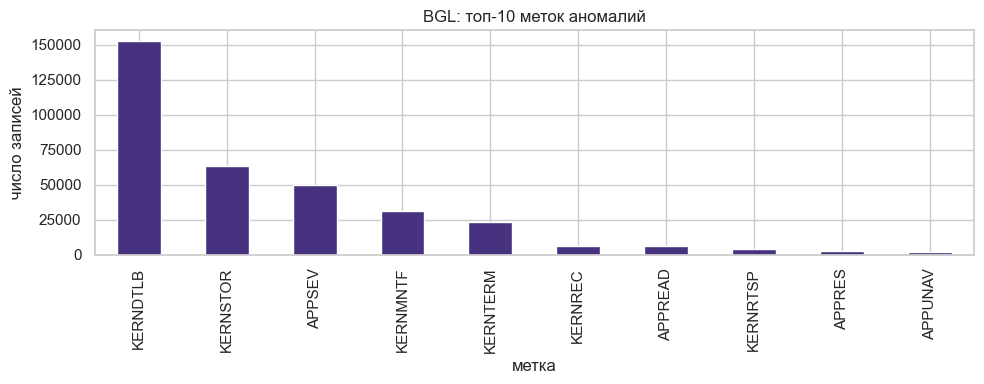

is_anomaly,False,True
severity,,
"0x00544eb8,",1.0000,0.0000
ERROR,1.0000,0.0000
FAILURE,0.9638,0.0362
FATAL,0.5924,0.4076
INFO,1.0000,0.0000
Kill,1.0000,0.0000
SEVERE,1.0000,0.0000
WARNING,1.0000,0.0000
microseconds,1.0000,0.0000


In [6]:
alert_tags = bgl.loc[bgl["is_anomaly"], "label"].value_counts()
alert_tags.head(10).plot(kind="bar", figsize=(10, 4), title="BGL: топ-10 меток аномалий")
plt.xlabel("метка")
plt.ylabel("число записей")
plt.tight_layout()
plt.show()

pd.crosstab(bgl["severity"], bgl["is_anomaly"], normalize="index").round(4)

In [7]:
bgl_templates, bgl_counts = template_table(bgl, top=20)
print("Уникальных шаблонов:", bgl_counts.size)
bgl_templates

Уникальных шаблонов: 46218


,template,count,percent
0,generating core.<*>,1706751,36.21
1,<*> double-hummer alignment exceptions,295764,6.27
2,<*> floating point alignment exceptions,267725,5.68
3,"CE sym <*>, at <*>, mask <*>",201206,4.27
4,data TLB error interrupt,152734,3.24
5,<*> microseconds spent in the rbs signal handl...,135092,2.87
6,<*> total interrupts. <*> critical input inter...,135092,2.87
7,instruction cache parity error corrected,105924,2.25
8,idoproxydb hit ASSERT condition: ASSERT expres...,84168,1.79
9,data storage interrupt,63493,1.35


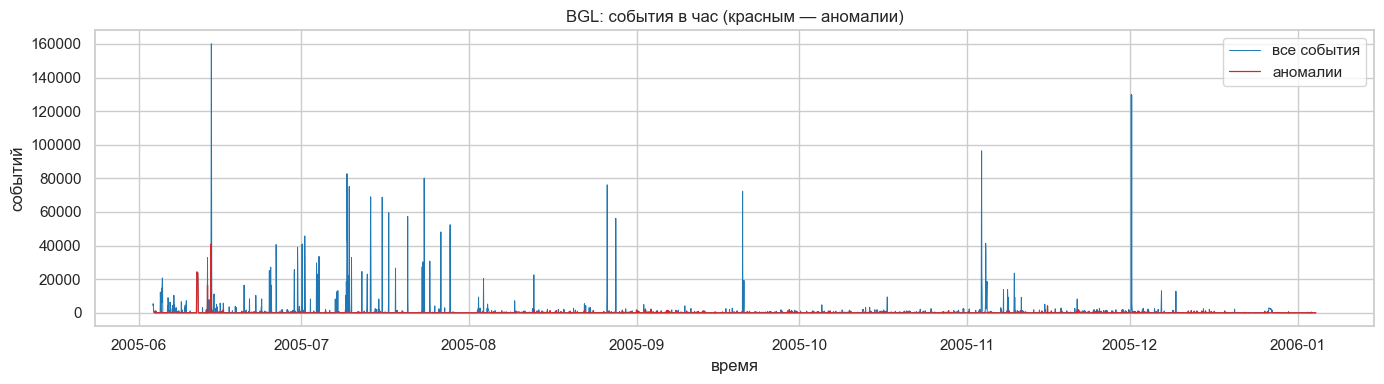

In [8]:
plot_events_per_interval(
    bgl, "1h", "BGL: события в час (красным — аномалии)", anomaly_col="is_anomaly"
)

## Windows — системные события Windows CBS

Датасет без меток аномалий и самый большой по объёму. Анализируем случайную выборку 1 000 000 строк, равномерно распределённых по файлу.

In [9]:
win = datasets["Windows"]
print("Колонки:", list(win.columns))
print("Пропусков по времени:", int(win["timestamp"].isna().sum()))
value_counts_df(win["log_level"], top=10)

Колонки: ['datetime', 'log_level', 'component', 'message', 'timestamp']
Пропусков по времени: 0


,count,percent
log_level,,
Info,998366,100.0
Error,2,0.0


In [10]:
win_components = value_counts_df(win["component"], top=15)
win_components

,count,percent
component,,
CBS,997117,99.87
CSI,1199,0.12
DPX,52,0.01


In [11]:
win_templates, win_counts = template_table(win, top=20)
print("Уникальных шаблонов:", win_counts.size)
win_templates

Уникальных шаблонов: 104808


,template,count,percent
0,Appl: Evaluating applicability block(non detec...,7109,0.71
1,Appl: Evaluating applicability block(non detec...,3946,0.40
2,Warning: Unrecognized packageExtended attribute.,1766,0.18
3,"Appl: Selfupdate, Component: amd64_microsoft-w...",1739,0.17
4,"Appl: Selfupdate, Component: amd64_microsoft-w...",1729,0.17
5,"Appl: Selfupdate, Component: amd64_microsoft-w...",1706,0.17
6,"Appl: Selfupdate, Component: amd64_microsoft-w...",1700,0.17
7,"Appl: Selfupdate, Component: amd64_microsoft-w...",1697,0.17
8,"Appl: Selfupdate, Component: amd64_microsoft-w...",1693,0.17
9,"Appl: Selfupdate, Component: amd64_microsoft-w...",1685,0.17


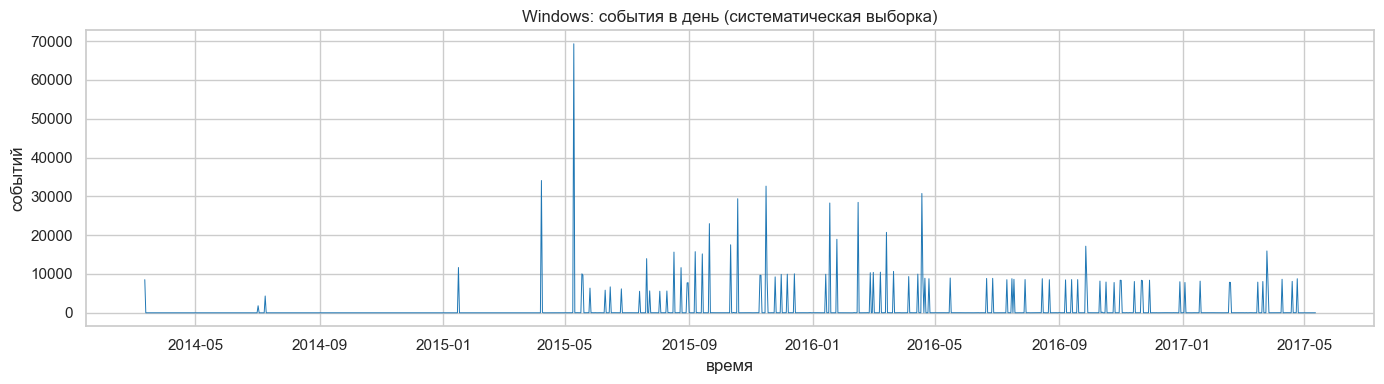

In [12]:
plot_events_per_interval(win, "1D", "Windows: события в день (систематическая выборка)")

## HealthApp — логи Android-приложения

Логи мобильного приложения за 10+ дней. Изучим компоненты, шаблоны событий и суточную цикличность.

In [13]:
health = datasets["HealthApp"]
print("Колонки:", list(health.columns))
print("Пропусков по времени:", int(health["timestamp"].isna().sum()))
value_counts_df(health["component"], top=15)

Колонки: ['datetime', 'component', 'thread_id', 'message', 'timestamp']
Пропусков по времени: 1


,count,percent
component,,
Step_LSC,81216,32.05
Step_SPUtils,56057,22.12
Step_ExtSDM,54857,21.65
Step_StandReportReceiver,26815,10.58
HiH_HiSyncControl,7694,3.04
HiH_DataStatManager,7237,2.86
HiH_HiHealthBinder,3456,1.36
HiH_HiHealthDataInsertStore,3385,1.34
Step_FlushableStepDataCache,3231,1.28


In [14]:
health_templates, health_counts = template_table(health, top=20)
print("Уникальных шаблонов:", health_counts.size)
health_templates

Уникальных шаблонов: 572


,template,count,percent
0,onExtend:<*> <*> <*> <*>,39753,15.69
1,onStandStepChanged <*>,30161,11.90
2,getTodayTotalDetailSteps = <*>##<*>##<*>##<*>...,27447,10.83
3,setTodayTotalDetailSteps=<*>##<*>##<*>##<*>##<...,27431,10.83
4,calculateCaloriesWithCache totalCalories=<*>,27426,10.82
5,calculateAltitudeWithCache totalAltitude=<*>,27426,10.82
6,REPORT : <*> <*> <*> <*>,23539,9.29
7,"new date =<*>, type=<*>,<*>,old=<*>",7064,2.79
8,processHandleBroadcastAction action:android.in...,6975,2.75
9,getBinderPackageName packageName = com.huawei....,3156,1.25


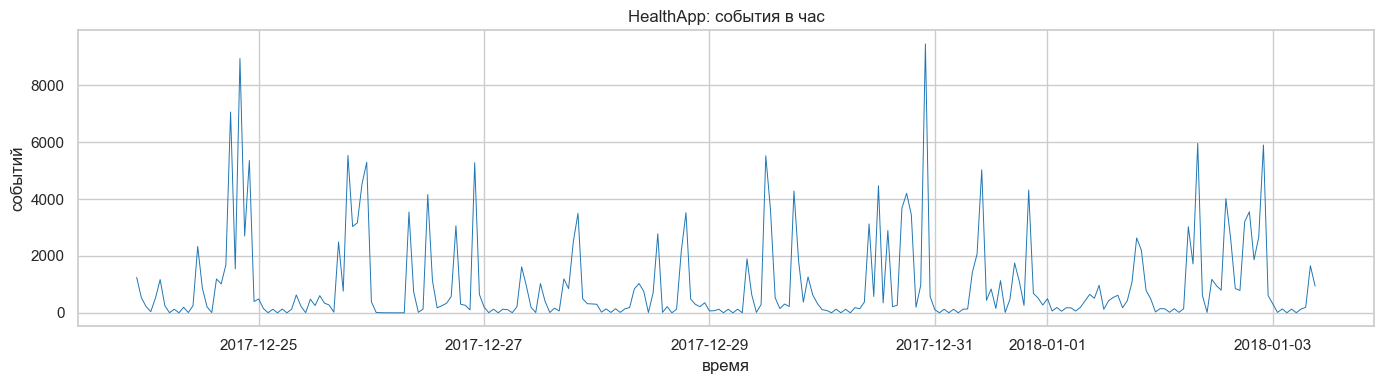

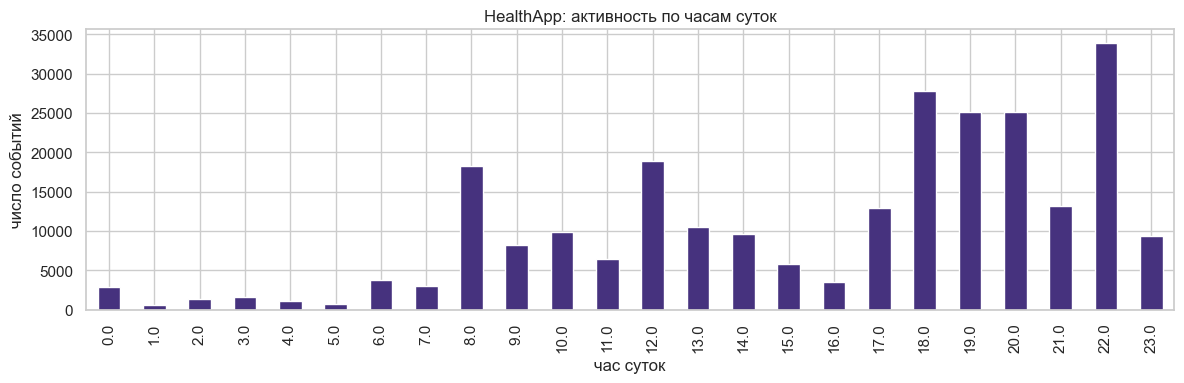

In [15]:
plot_events_per_interval(health, "1h", "HealthApp: события в час")

hour_counts = health["timestamp"].dt.hour.value_counts().sort_index()
hour_counts.plot(kind="bar", figsize=(12, 4), title="HealthApp: активность по часам суток")
plt.xlabel("час суток")
plt.ylabel("число событий")
plt.tight_layout()
plt.show()

## Apache — веб-сервер Apache (error log)

Журнал ошибок Apache. Изучим уровни логирования, шаблоны ошибок и распределение по дням.

In [16]:
apache = datasets["Apache"]
print("Колонки:", list(apache.columns))
print("Пропусков по времени:", int(apache["timestamp"].isna().sum()))
value_counts_df(apache["log_level"], top=10)

Колонки: ['ts', 'log_level', 'message', 'timestamp']
Пропусков по времени: 0


,count,percent
log_level,,
error,38081,73.23
notice,13755,26.45
warn,168,0.32


In [17]:
apache_templates, apache_counts = template_table(apache, top=20)
print("Уникальных шаблонов:", apache_counts.size)
apache_templates

Уникальных шаблонов: 150


,template,count,percent
0,[client <*>] File does not exist: <*>,19671,37.83
1,[client <*>] Directory index forbidden by rule...,6709,12.90
2,jk2_init() Found child <*> in scoreboard slot <*>,6325,12.16
3,workerEnv.init() ok <*>,5691,10.94
4,mod_jk child workerEnv in error state <*>,4310,8.29
5,[client <*>] script not found or unable to sta...,3141,6.04
6,mod_jk2 Shutting down,1324,2.55
7,jk2_init() Can't find child <*> in scoreboard,969,1.86
8,mod_jk child init <*> -<*>,939,1.81
9,[client <*>] File does not exist: <*> script n...,749,1.44


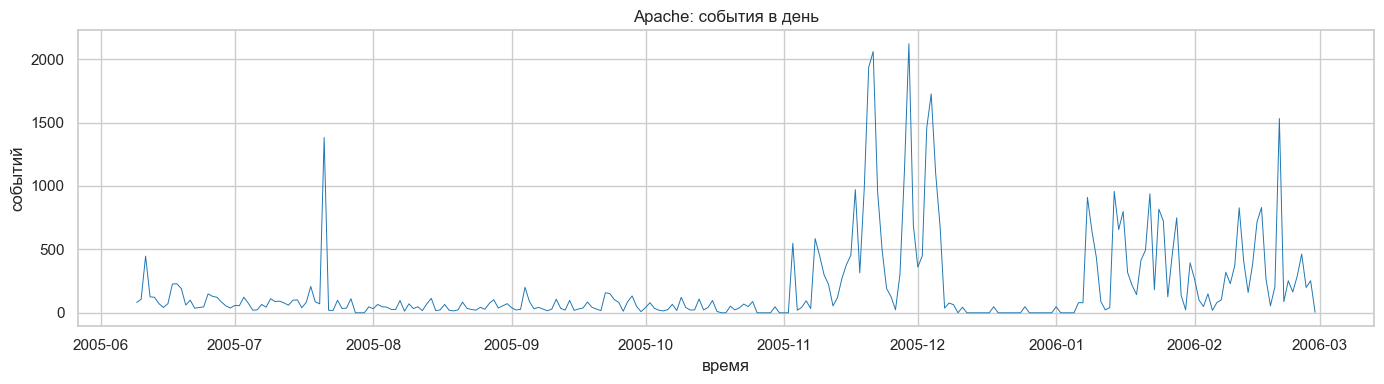

In [18]:
plot_events_per_interval(apache, "1D", "Apache: события в день")

## Текстовая статистика

Распределение длины сообщений по датасетам (в логарифмической шкале).

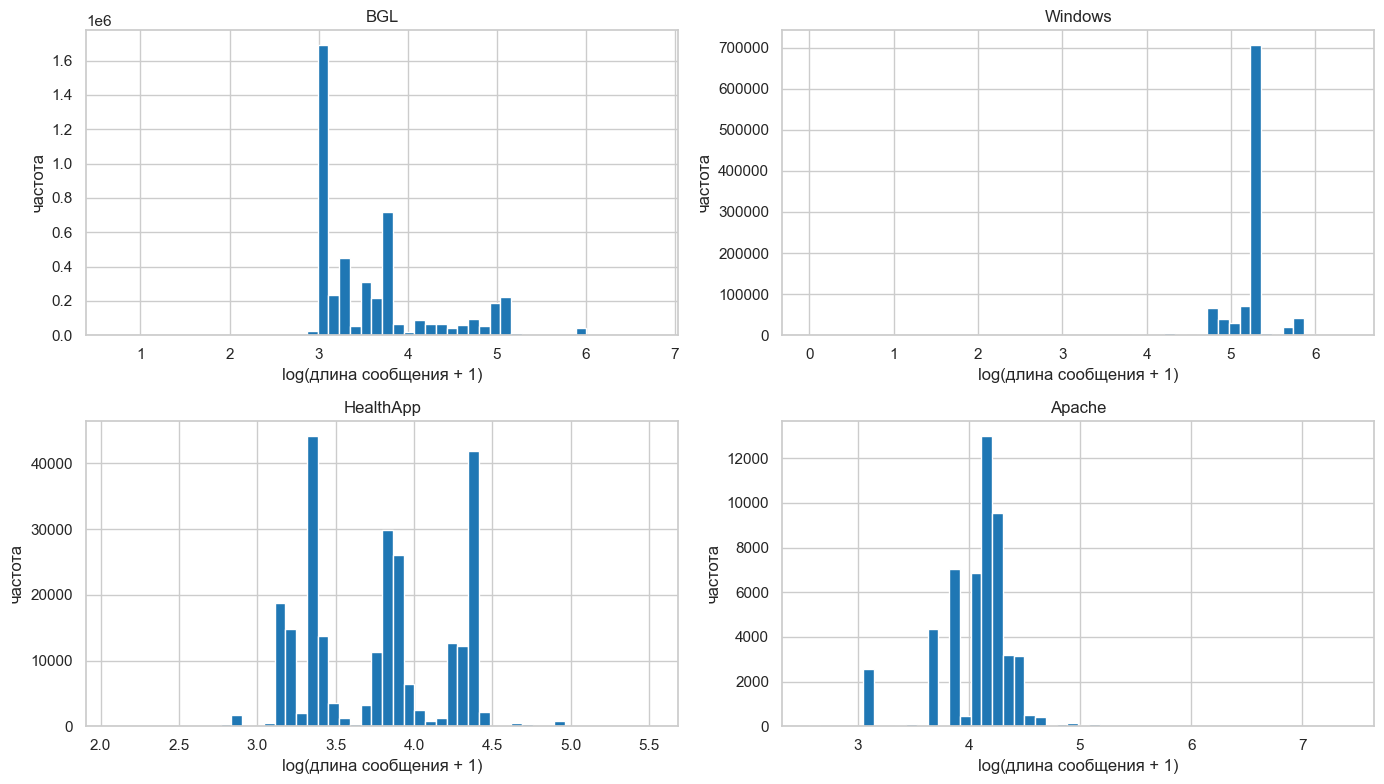

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (name, df) in zip(axes.ravel(), datasets.items()):
    lengths = df["message"].str.len()
    ax.hist(np.log1p(lengths), bins=50, color="#1f77b4")
    ax.set_title(name)
    ax.set_xlabel("log(длина сообщения + 1)")
    ax.set_ylabel("частота")
plt.tight_layout()
plt.show()

## Сводка и выводы

In [20]:
summary_rows = []
for name, df in datasets.items():
    counts = extract_templates(df["message"]).value_counts()
    top10_share = counts.head(10).sum() / counts.sum()
    summary_rows.append(
        {
            "датасет": name,
            "записей": len(df),
            "уникальных шаблонов": counts.size,
            "доля топ-10 шаблонов, %": round(top10_share * 100, 1),
            "доля аномалий, %": round(df["is_anomaly"].mean() * 100, 2) if "is_anomaly" in df.columns else "-",
        }
    )
pd.DataFrame(summary_rows).set_index("датасет")

,записей,уникальных шаблонов,"доля топ-10 шаблонов, %","доля аномалий, %"
датасет,,,,
BGL,4713493,46218,66.8,7.39
Windows,998368,104808,2.5,-
HealthApp,253395,572,87.0,-
Apache,52004,150,95.8,-


## Выводы

1. **Разные домены — разные масштаб и структура строк.** Объём варьируется от 56 тыс. строк (Apache) до 114 млн (Windows), поэтому загрузка каждого датасета вынесена в отдельный парсер.

2. **BGL — единственный размеченный датасет.** Метка аномалии хранится в первом поле строки (`-` — норма, всё остальное — алерт). Доля аномалий ≈ 7.4 %, и во времени они распределены неравномерно: всплески алертов совпадают со сбойными периодами. Это готовый supervised-бенчмарк.

3. **Windows, HealthApp и Apache не размечены**, поэтому для них детекция аномалий должна быть unsupervised — например, по редким шаблонам событий или отклонениям частот от нормы.

4. **Распределение шаблонов событий сильно скошено.** В каждом датасете небольшое число шаблонов покрывает основную долю лога, поэтому идентификатор шаблона (event id) — естественный категориальный признак.

5. **Выражена временная структура:** суточная цикличность у HealthApp, редкие всплески у Apache и BGL. Признак «число событий в окне» и производные от него информативны для детекции аномалий.

6. **Лёгкий токенизатор шаблонов** (замена чисел, IP-адресов и путей на `<*>`) уже даёт осмысленные event-шаблоны. При необходимости его можно заменить на Drain, не меняя пайплайн загрузки данных.

Дальнейшие шаги: построить признаковое представление (event id + агрегаты по временным окнам) и обучить модель детекции аномалий.